In [1]:
%pip install --upgrade pip
%pip install pandas numpy matplotlib seaborn plotly scikit-learn streamlit

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


#install pacakages 


In [2]:
%pip install scikit-learn==1.6.0 streamlit==1.30.0 pandas==2.0.3 numpy==1.26.4 matplotlib==3.8.2 seaborn==0.12.3 plotly==5.17.0

  Using cached scikit_learn-1.6.0-cp313-cp313-macosx_12_0_arm64.whl.metadata (31 kB)
  Using cached streamlit-1.30.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached pandas-2.0.3.tar.gz (5.3 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [23 lines of output]
      Traceback (most recent call last):
        File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 406, in <module>
          main()
          ~~~~^^
        File "/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 381, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "/

#import all important libraries 

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

EDA

In [4]:
import pandas as pd
print("Pandas:", pd.__version__)

import numpy as np
print("NumPy:", np.__version__)

import matplotlib.pyplot as plt
print("Matplotlib: Working")

import seaborn as sns
print("Seaborn: Working")

import plotly.express as px
print("Plotly: Working")

from sklearn.model_selection import train_test_split
print("Scikit-learn: Working")

import streamlit as st
print("Streamlit: Working")

Pandas: 3.1.1
NumPy: 2.5.5
Matplotlib: Working
Seaborn: Working
Plotly: Working
Scikit-learn: Working
Streamlit: Working


In [5]:
df = pd.read_csv("flight_data_sample.csv")

df.head()

,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,dest,...,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,is_delayed
0,3,4,1,2024-03-04,OO,3821.0,GEG,"Spokane, WA",Washington,SLC,...,113.0,125.0,76.0,546.0,0,0,0,0,0,0
1,12,9,1,2024-12-09,OO,5544.0,ORD,"Chicago, IL",Illinois,FSD,...,106.0,95.0,75.0,462.0,101,0,0,0,0,1
2,9,5,4,2024-09-05,YX,3668.0,ORD,"Chicago, IL",Illinois,IND,...,73.0,66.0,36.0,177.0,0,0,0,0,0,0
3,5,14,2,2024-05-14,AA,1688.0,ABQ,"Albuquerque, NM",New Mexico,DFW,...,110.0,95.0,76.0,569.0,0,0,0,0,0,0
4,6,14,5,2024-06-14,WN,1220.0,MKE,"Milwaukee, WI",Wisconsin,BNA,...,90.0,79.0,65.0,475.0,0,0,0,0,0,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550000 entries, 0 to 549999
Data columns (total 34 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                550000 non-null  int64  
 1   day_of_month         550000 non-null  int64  
 2   day_of_week          550000 non-null  int64  
 3   fl_date              550000 non-null  str    
 4   op_unique_carrier    550000 non-null  str    
 5   op_carrier_fl_num    550000 non-null  float64
 6   origin               550000 non-null  str    
 7   origin_city_name     550000 non-null  str    
 8   origin_state_nm      550000 non-null  str    
 9   dest                 550000 non-null  str    
 10  dest_city_name       550000 non-null  str    
 11  dest_state_nm        550000 non-null  str    
 12  crs_dep_time         550000 non-null  int64  
 13  dep_time             550000 non-null  float64
 14  dep_delay            550000 non-null  float64
 15  taxi_out             550000 

In [7]:
df.isna().sum()

month                  0
day_of_month           0
day_of_week            0
fl_date                0
op_unique_carrier      0
op_carrier_fl_num      0
origin                 0
origin_city_name       0
origin_state_nm        0
dest                   0
dest_city_name         0
dest_state_nm          0
crs_dep_time           0
dep_time               0
dep_delay              0
taxi_out               0
wheels_off             0
wheels_on              0
taxi_in                0
crs_arr_time           0
arr_time               0
arr_delay              0
cancelled              0
diverted               0
crs_elapsed_time       0
actual_elapsed_time    0
air_time               0
distance               0
carrier_delay          0
weather_delay          0
nas_delay              0
security_delay         0
late_aircraft_delay    0
is_delayed             0
dtype: int64

In [8]:
df.describe()

,month,day_of_month,day_of_week,op_carrier_fl_num,crs_dep_time,dep_time,dep_delay,taxi_out,wheels_off,wheels_on,...,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,is_delayed
count,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,...,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000
mean,6.599293,15.801422,3.980420,2502.437822,1326.721229,1331.407124,12.576658,17.894951,1354.266656,1459.497880,...,146.673298,141.169400,114.968225,833.547931,5.091711,0.861564,2.785764,0.025169,6.104242,0.207753
std,3.396034,8.795506,2.011835,1648.733678,492.161059,508.901968,55.200136,9.667328,511.556542,539.633332,...,72.304322,72.200365,70.272071,595.736321,34.583158,15.037031,15.305672,1.176599,32.183465,0.405699
min,1.000000,1.000000,1.000000,1.000000,4.000000,1.000000,-43.000000,1.000000,1.000000,1.000000,...,23.000000,16.000000,8.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,8.000000,2.000000,1155.000000,907.000000,909.000000,-6.000000,12.000000,925.000000,1043.000000,...,93.000000,88.000000,63.000000,399.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.000000,16.000000,4.000000,2227.000000,1320.000000,1325.000000,-2.000000,15.000000,1339.000000,1501.000000,...,130.000000,125.000000,98.000000,679.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,10.000000,23.000000,6.000000,3713.000000,1735.000000,1746.000000,9.000000,21.000000,1801.000000,1914.000000,...,177.000000,172.000000,145.000000,1069.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,12.000000,31.000000,7.000000,8819.000000,2359.000000,2400.000000,2640.000000,178.000000,2400.000000,2400.000000,...,707.000000,755.000000,692.000000,5095.000000,2548.000000,1773.000000,1082.000000,306.000000,2506.000000,1.000000


In [9]:
df = df[[
    'month',
    'day_of_month',
    'day_of_week',
    'op_unique_carrier',
    'origin',
    'dest',
    'crs_dep_time',
    'crs_arr_time',
    'crs_elapsed_time',
    'distance',
    'is_delayed'
]]

In [10]:
df_new=df.copy()

#cleandata

In [11]:
df_new.duplicated().sum()

np.int64(1)

In [12]:
df_new.dtypes

month                  int64
day_of_month           int64
day_of_week            int64
op_unique_carrier        str
origin                   str
dest                     str
crs_dep_time           int64
crs_arr_time           int64
crs_elapsed_time     float64
distance             float64
is_delayed             int64
dtype: object

In [13]:
df_new['op_unique_carrier'].value_counts()

op_unique_carrier
WN    110981
DL     79041
AA     76590
UA     58874
OO     57933
YX     23154
MQ     21707
NK     19995
B6     18779
AS     18739
OH     17551
F9     16121
9E     15431
G4      8984
HA      6120
Name: count, dtype: int64

In [14]:
df_new.describe()

,month,day_of_month,day_of_week,crs_dep_time,crs_arr_time,crs_elapsed_time,distance,is_delayed
count,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000,550000.000000
mean,6.599293,15.801422,3.980420,1326.721229,1491.218767,146.673298,833.547931,0.207753
std,3.396034,8.795506,2.011835,492.161059,518.257816,72.304322,595.736321,0.405699
min,1.000000,1.000000,1.000000,4.000000,1.000000,23.000000,31.000000,0.000000
25%,4.000000,8.000000,2.000000,907.000000,1105.000000,93.000000,399.000000,0.000000
50%,7.000000,16.000000,4.000000,1320.000000,1516.000000,130.000000,679.000000,0.000000
75%,10.000000,23.000000,6.000000,1735.000000,1925.000000,177.000000,1069.000000,0.000000
max,12.000000,31.000000,7.000000,2359.000000,2359.000000,707.000000,5095.000000,1.000000


In [15]:
df_new.drop_duplicates(inplace=True)

/var/folders/cp/p71k5bkj4qd1ysd4x2k0jsd80000gn/T/ipykernel_8139/3069802320.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_new.drop_duplicates(inplace=True)


In [16]:
df_new.duplicated().sum()

np.int64(0)

#target-variable

In [17]:
df_new['is_delayed'].value_counts()

is_delayed
0    435735
1    114264
Name: count, dtype: int64

In [18]:
df_new['is_delayed'].value_counts(normalize=True) * 100

is_delayed
0    79.224689
1    20.775311
Name: proportion, dtype: float64

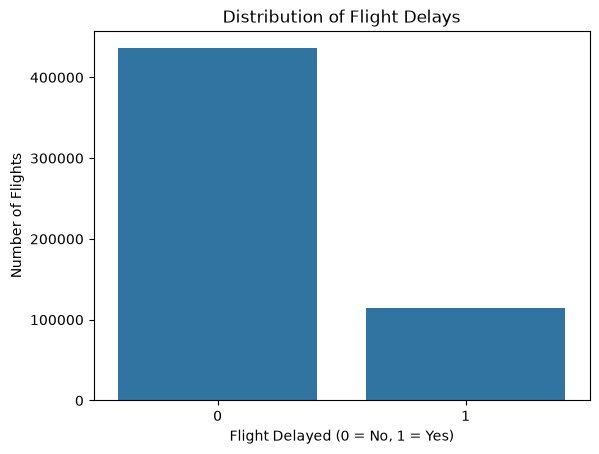

In [19]:
sns.countplot(data=df_new, x='is_delayed')

plt.title('Distribution of Flight Delays')
plt.xlabel('Flight Delayed (0 = No, 1 = Yes)')
plt.ylabel('Number of Flights')
plt.show()

In [ ]:
g = sns.pairplot(
    df_new,
    hue='is_delayed',
    palette='Set1'
)

plt.show()

KeyboardInterrupt: 

#vizualization

In [20]:
df_delayed = df_new[df_new['is_delayed'] == 1]

/var/folders/cp/p71k5bkj4qd1ysd4x2k0jsd80000gn/T/ipykernel_8139/2391669570.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


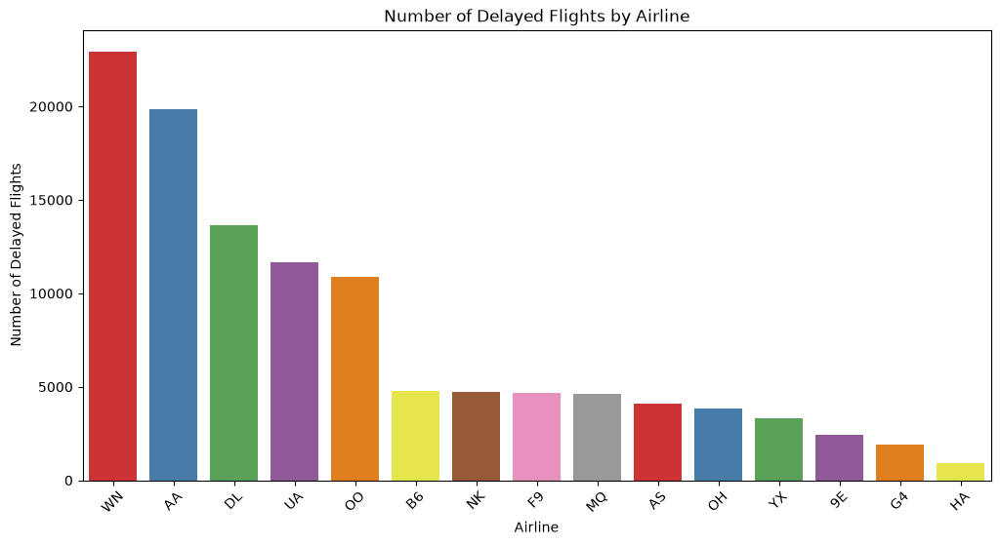

In [21]:
plt.figure(figsize=(12,6))

sns.countplot(
    x='op_unique_carrier',
    data=df_delayed,
    palette='Set1',
    order=df_delayed['op_unique_carrier'].value_counts().index
)

plt.title('Number of Delayed Flights by Airline')
plt.xlabel('Airline')
plt.ylabel('Number of Delayed Flights')
plt.xticks(rotation=45)
plt.show()

#delay-rates

In [22]:
airline_delay_rate = df_new.groupby('op_unique_carrier')['is_delayed'].mean() * 100

airline_delay_rate.sort_values(ascending=False)

op_unique_carrier
F9    29.086285
AA    25.904165
B6    25.310187
NK    23.590898
AS    21.895512
OH    21.793630
G4    21.471505
MQ    21.278850
WN    20.678314
UA    19.816897
OO    18.739211
DL    17.246745
9E    15.818806
HA    15.392157
YX    14.261035
Name: is_delayed, dtype: float64

/var/folders/cp/p71k5bkj4qd1ysd4x2k0jsd80000gn/T/ipykernel_8139/2698960654.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


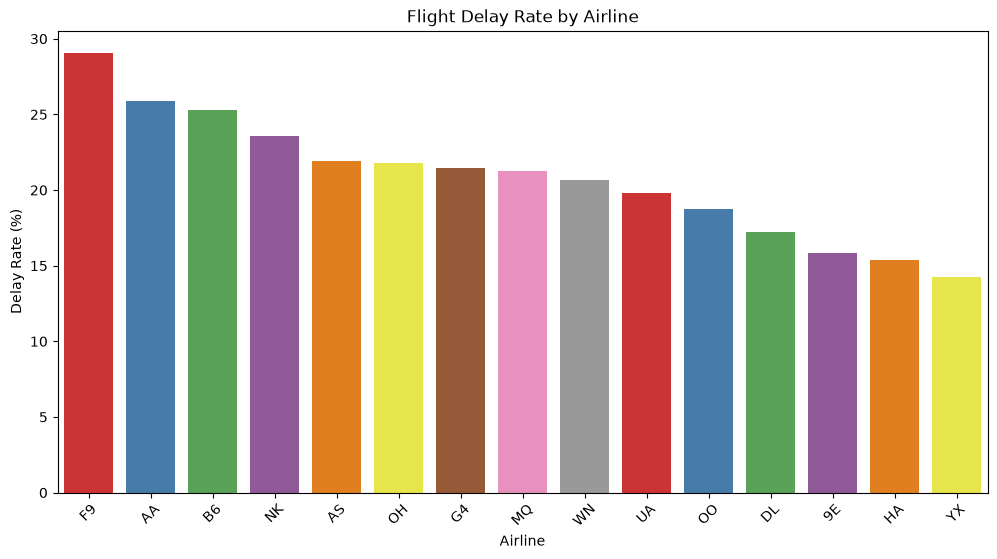

In [23]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=airline_delay_rate.sort_values(ascending=False).index,
    y=airline_delay_rate.sort_values(ascending=False).values,
    palette='Set1'
)

plt.title('Flight Delay Rate by Airline')
plt.xlabel('Airline')
plt.ylabel('Delay Rate (%)')
plt.xticks(rotation=45)
plt.show()

#day of the week

/var/folders/cp/p71k5bkj4qd1ysd4x2k0jsd80000gn/T/ipykernel_8139/2296582948.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


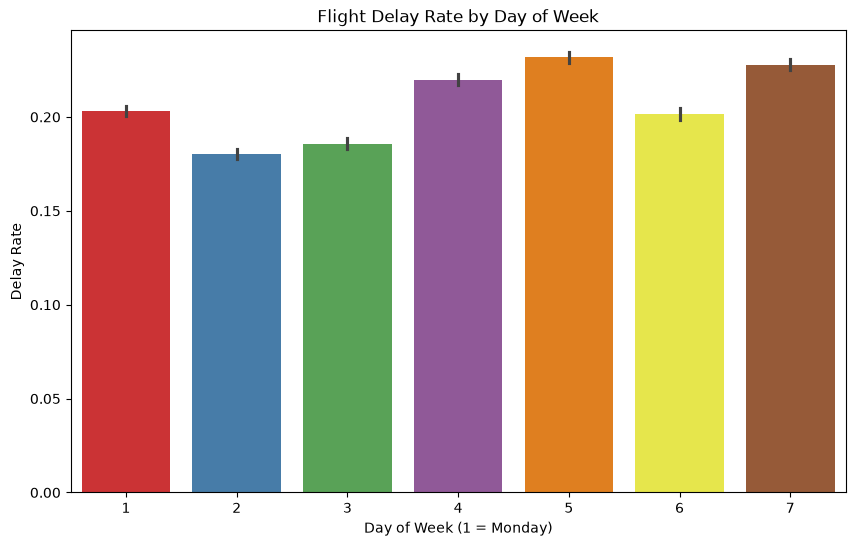

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='day_of_week',
    y='is_delayed',
    data=df_new,
    palette='Set1'
)

plt.title('Flight Delay Rate by Day of Week')
plt.xlabel('Day of Week (1 = Monday)')
plt.ylabel('Delay Rate')
plt.show()

#flight delay by month

/var/folders/cp/p71k5bkj4qd1ysd4x2k0jsd80000gn/T/ipykernel_8139/1923397446.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


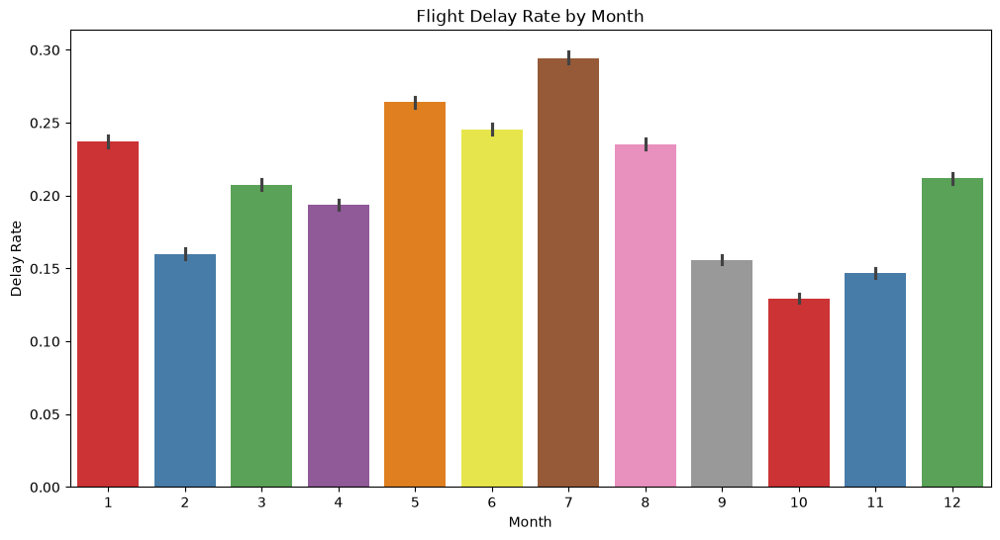

In [25]:
plt.figure(figsize=(12,6))

sns.barplot(
    x='month',
    y='is_delayed',
    data=df_new,
    palette='Set1'
)

plt.title('Flight Delay Rate by Month')
plt.xlabel('Month')
plt.ylabel('Delay Rate')
plt.show()

In [26]:
%pip install --upgrade nbformat

Note: you may need to restart the kernel to use updated packages.


#Flight delay distribution by scheduled departure time

In [27]:
import plotly.express as px
px.histogram(
    df_new,
    x='crs_dep_time',
    color='is_delayed',
    marginal='box',
    nbins=30,
    title='Scheduled Departure Time Distribution by Flight Delay Status'
)

#Scheduled arrival time

In [28]:
px.histogram(
    df_new,
    x='crs_arr_time',
    color='is_delayed',
    marginal='box',
    nbins=30,
    title='Scheduled Arrival Time Distribution by Flight Delay Status'
)

#Scheduled flight duration

In [29]:
px.histogram(
    df_new,
    x='crs_elapsed_time',
    color='is_delayed',
    marginal='box',
    nbins=30,
    title='Scheduled Flight Duration Distribution by Flight Delay Status'
)

Flight distance

In [30]:
px.histogram(
    df_new,
    x='distance',
    color='is_delayed',
    marginal='box',
    nbins=30,
    title='Flight Distance Distribution by Flight Delay Status'
)

#Split input and output

In [44]:
X = df_new.drop(['is_delayed'], axis=1)
y = df_new['is_delayed']

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [46]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

categorical_features = X.select_dtypes(include=['str']).columns

print("Numerical features:")
print(numerical_features)

print("Categorical features:")
print(categorical_features)

Numerical features:
Index(['month', 'day_of_month', 'day_of_week', 'crs_dep_time', 'crs_arr_time',
       'crs_elapsed_time', 'distance'],
      dtype='str')
Categorical features:
Index(['op_unique_carrier', 'origin', 'dest'], dtype='str')


In [47]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [48]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [49]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [50]:
column_transformer = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [51]:
column_transformer

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [52]:
X_train_processed = column_transformer.fit_transform(X_train)

X_test_processed = column_transformer.transform(X_test)

#apply the modeling 

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [56]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_processed, y_train)

y_pred = lr.predict(X_test_processed)

In [57]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Classification report for training:\n",
      classification_report(y_train, lr.predict(X_train_processed)))

print("Classification report for testing:\n",
      classification_report(y_test, y_pred))

print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.792290909090909
Classification report for training:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88    348588
           1       0.47      0.00      0.01     91411

    accuracy                           0.79    439999
   macro avg       0.63      0.50      0.45    439999
weighted avg       0.73      0.79      0.70    439999

Classification report for testing:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88     87147
           1       0.51      0.00      0.01     22853

    accuracy                           0.79    110000
   macro avg       0.65      0.50      0.45    110000
weighted avg       0.73      0.79      0.70    110000

Confusion matrix:
 [[87041   106]
 [22742   111]]


In [68]:
from sklearn.model_selection import train_test_split

X_train_knn, _, y_train_knn, _ = train_test_split(
    X_train_processed,
    y_train,
    train_size=300000,
    stratify=y_train,
    random_state=42
)

X_test_knn, _, y_test_knn, _ = train_test_split(
    X_test_processed,
    y_test,
    train_size=10000,
    stratify=y_test,
    random_state=42
)

In [69]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_knn, y_train_knn)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [70]:
y_pred_knn = knn.predict(X_test_knn)

In [71]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test_knn, y_pred_knn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_knn, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test_knn, y_pred_knn))

Accuracy: 0.7646

Confusion Matrix:
[[7332  590]
 [1764  314]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.93      0.86      7922
           1       0.35      0.15      0.21      2078

    accuracy                           0.76     10000
   macro avg       0.58      0.54      0.54     10000
weighted avg       0.71      0.76      0.73     10000



In [72]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=5
)

rf.fit(X_train_processed, y_train)

y_pred_rf = rf.predict(X_test_processed)

In [73]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("Classification report for training:\n",
      classification_report(y_train, rf.predict(X_train_processed)))

print("Classification report for testing:\n",
      classification_report(y_test, y_pred_rf))

print("Confusion matrix:\n",
      confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.7922454545454546
Classification report for training:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88    348588
           1       0.00      0.00      0.00     91411

    accuracy                           0.79    439999
   macro avg       0.40      0.50      0.44    439999
weighted avg       0.63      0.79      0.70    439999

Classification report for testing:
               precision    recall  f1-score   support

           0       0.79      1.00      0.88     87147
           1       0.00      0.00      0.00     22853

    accuracy                           0.79    110000
   macro avg       0.40      0.50      0.44    110000
weighted avg       0.63      0.79      0.70    110000

Confusion matrix:
 [[87147     0]
 [22853     0]]


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

#balance

In [74]:
rf_balanced = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=5,
    class_weight='balanced'
)

rf_balanced.fit(X_train_processed, y_train)

y_pred_rf_balanced = rf_balanced.predict(X_test_processed)

In [75]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_balanced))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_balanced))

Accuracy: 0.593709090909091

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.58      0.70     87147
           1       0.28      0.63      0.39     22853

    accuracy                           0.59    110000
   macro avg       0.57      0.61      0.54    110000
weighted avg       0.74      0.59      0.63    110000


Confusion Matrix:
[[50931 36216]
 [ 8476 14377]]


In [76]:
rf_balanced_2 = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=10,
    class_weight='balanced'
)

rf_balanced_2.fit(X_train_processed, y_train)

y_pred_rf_balanced_2 = rf_balanced_2.predict(X_test_processed)

In [77]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_rf_balanced_2))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_balanced_2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_balanced_2))

Accuracy: 0.6070909090909091

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.60      0.71     87147
           1       0.29      0.62      0.40     22853

    accuracy                           0.61    110000
   macro avg       0.58      0.61      0.55    110000
weighted avg       0.74      0.61      0.64    110000


Confusion Matrix:
[[52565 34582]
 [ 8638 14215]]


#cross validation

In [78]:
from sklearn.model_selection import StratifiedKFold, cross_validate

kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    rf_balanced_2,
    X_train_processed,
    y_train,
    cv=kfold,
    scoring=['accuracy', 'precision', 'recall', 'f1'],
    return_train_score=True
)

scores

{'fit_time': array([12.93368101, 12.5288012 , 11.88070607, 11.74366069, 11.63037109]),
 'score_time': array([0.28296804, 0.27333593, 0.27458787, 0.27107835, 0.26739717]),
 'test_accuracy': array([0.59603409, 0.603125  , 0.61276136, 0.59793182, 0.60405232]),
 'train_accuracy': array([0.60178864, 0.61075458, 0.61664664, 0.60507842, 0.60820739]),
 'test_precision': array([0.28778605, 0.29054343, 0.29415904, 0.28990244, 0.29257784]),
 'train_precision': array([0.29400522, 0.2989609 , 0.30073181, 0.29622665, 0.29741697]),
 'test_recall': array([0.64041133, 0.63138606, 0.61732852, 0.64524422, 0.63887977]),
 'train_recall': array([0.65421379, 0.64955079, 0.63780443, 0.65485177, 0.65027554]),
 'test_f1': array([0.39711693, 0.39795901, 0.39845364, 0.40006104, 0.40135388]),
 'train_f1': array([0.40569166, 0.40946314, 0.40873878, 0.40792545, 0.40815556])}

# Cross-validation evaluates the model across 5 different training and validation splits.
# The model achieved an average accuracy of 60.28% and recall of 63.47%.
# The consistent scores across folds suggest stable performance.

#hyper parameter tuning 

In [79]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7]
}

grid_search = GridSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ),
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_processed, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information pr

In [80]:
print("Best Parameters:", grid_search.best_params_)
print("Best F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 7, 'n_estimators': 100}
Best F1 Score: 0.39717929220611387


In [83]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Use the best Random Forest model from GridSearchCV
rf = grid_search.best_estimator_

# Train the model
rf.fit(X_train_processed, y_train)

# Predict using the testing data
y_pred = rf.predict(X_test_processed)

# Classification report for training
print("Classification Report Training:\n",
      classification_report(y_train, rf.predict(X_train_processed)))

# Classification report for testing
print("Classification Report Testing:\n",
      classification_report(y_test, y_pred))

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:\n",
      confusion_matrix(y_test, y_pred))

Classification Report Training:
               precision    recall  f1-score   support

           0       0.86      0.59      0.70    348588
           1       0.29      0.64      0.40     91411

    accuracy                           0.60    439999
   macro avg       0.58      0.62      0.55    439999
weighted avg       0.74      0.60      0.64    439999

Classification Report Testing:
               precision    recall  f1-score   support

           0       0.86      0.59      0.70     87147
           1       0.29      0.63      0.39     22853

    accuracy                           0.60    110000
   macro avg       0.57      0.61      0.55    110000
weighted avg       0.74      0.60      0.64    110000

Accuracy: 0.5989
Confusion Matrix:
 [[51554 35593]
 [ 8528 14325]]


#creating the deployment pipeline for Flight Delay Prediction

In [88]:
df_new

,month,day_of_month,day_of_week,op_unique_carrier,origin,dest,crs_dep_time,crs_arr_time,crs_elapsed_time,distance,is_delayed
0,3,4,1,OO,GEG,SLC,1700,1953,113.0,546.0,0
1,12,9,1,OO,ORD,FSD,1250,1436,106.0,462.0,1
2,9,5,4,YX,ORD,IND,716,929,73.0,177.0,0
3,5,14,2,AA,ABQ,DFW,500,750,110.0,569.0,0
4,6,14,5,WN,MKE,BNA,530,700,90.0,475.0,0
...,...,...,...,...,...,...,...,...,...,...,...
549995,7,13,6,WN,DAL,SRQ,1325,1650,145.0,934.0,0
549996,4,4,4,YX,EWR,MEM,829,1031,182.0,946.0,0
549997,3,24,7,OO,BTR,DFW,1942,2123,101.0,383.0,0
549998,12,6,5,WN,MDW,MCO,600,945,165.0,990.0,0


In [89]:
df_new.isna().sum()

month                0
day_of_month         0
day_of_week          0
op_unique_carrier    0
origin               0
dest                 0
crs_dep_time         0
crs_arr_time         0
crs_elapsed_time     0
distance             0
is_delayed           0
dtype: int64

In [90]:
X = df_new.drop('is_delayed', axis=1)
y = df_new['is_delayed']

In [91]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [92]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

categorical_features = X.select_dtypes(include=['object', 'str']).columns

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: Index(['month', 'day_of_month', 'day_of_week', 'crs_dep_time', 'crs_arr_time',
       'crs_elapsed_time', 'distance'],
      dtype='str')
Categorical features: Index(['op_unique_carrier', 'origin', 'dest'], dtype='str')


In [84]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

#Create the numerical pipeline

In [95]:
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False))
])

numerical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

In [96]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

categorical_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('onehot', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto acc

In [105]:
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [99]:
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_estimators=grid_search.best_params_['n_estimators'],
        max_depth=grid_search.best_params_['max_depth'],
        class_weight='balanced'
    ))
])

In [100]:
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['month','day_of_month','day_of_week',...,'crs_arr_time', 'crs_elapsed_time','distance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [106]:
model_pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['month','day_of_month','day_of_week',...,'crs_arr_time', 'crs_elapsed_time','distance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [107]:
y_pred = model_pipeline.predict(X_test)

#save the model 

In [109]:
import joblib

joblib.dump(model_pipeline, 'flight_delay_model.pkl')

['flight_delay_model.pkl']

In [110]:
import joblib

classifier = joblib.load('flight_delay_model.pkl')

# making a prediction using new flight information

In [121]:
import pandas as pd

classifier.predict(pd.DataFrame({
    'month': [7],
    'day_of_month': [15],
    'day_of_week': [3],
    'op_unique_carrier': ['WN'],
    'origin': ['DAL'],
    'dest': ['HOU'],
    'crs_dep_time': [900],
    'crs_arr_time': [1010],
    'crs_elapsed_time': [70],
    'distance': [239]
}))

array([0])

In [138]:

import streamlit as st
import joblib
import pandas as pd
from datetime import time

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Flight Delay Prediction",
    page_icon="✈️",
    layout="wide"
)

# --------------------------------------------------
# CUSTOM DESIGN
# --------------------------------------------------

st.markdown("""
<style>

.stApp {
    background: linear-gradient(135deg, #071426, #102B49);
    color: #FFFFFF;
}

[data-testid="stHeader"] {
    background: transparent;
}

h1, h2, h3, p, label {
    color: #FFFFFF !important;
}

.main-title {
    background: linear-gradient(90deg, #123B65, #087EAA);
    padding: 30px;
    border-radius: 16px;
    text-align: center;
    margin-bottom: 25px;
    border: 1px solid #28577E;
}

.main-title h1 {
    color: white !important;
    font-size: 38px;
    margin-bottom: 8px;
}

.main-title p {
    color: #D5E9F7 !important;
    font-size: 16px;
}

.section-title {
    color: #63C5F1 !important;
    font-size: 22px;
    font-weight: bold;
    margin-bottom: 15px;
}

.stSelectbox div[data-baseweb="select"] > div,
.stDateInput input,
.stTimeInput input {
    background-color: #193653;
    color: white;
    border-radius: 8px;
}

[data-baseweb="select"] span {
    color: white !important;
}

.stButton button {
    background: linear-gradient(90deg, #087EAA, #1769AA);
    color: white;
    border: none;
    border-radius: 10px;
    height: 50px;
    font-size: 17px;
    font-weight: bold;
    width: 100%;
}

.stButton button:hover {
    background: #2196C7;
    color: white;
}

[data-testid="stMetric"] {
    background-color: #142D48;
    padding: 18px;
    border-radius: 12px;
    border: 1px solid #294967;
}

[data-testid="stMetricLabel"],
[data-testid="stMetricValue"] {
    color: white !important;
}

hr {
    border-color: #294967;
}

[data-testid="stAlert"] {
    border-radius: 12px;
}

</style>
""", unsafe_allow_html=True)


# --------------------------------------------------
# LOAD DATASET AND TRAINED MODEL
# --------------------------------------------------

@st.cache_data
def load_data():
    return pd.read_csv("flight_data_sample.csv")


@st.cache_resource
def load_model():
    return joblib.load("flight_delay_model.pkl")


df = load_data()
classifier = load_model()


# --------------------------------------------------
# AIRLINE NAMES
# --------------------------------------------------

carrier_names = {
    "9E": "Endeavor Air",
    "AA": "American Airlines",
    "AS": "Alaska Airlines",
    "B6": "JetBlue Airways",
    "DL": "Delta Air Lines",
    "F9": "Frontier Airlines",
    "G4": "Allegiant Air",
    "HA": "Hawaiian Airlines",
    "MQ": "Envoy Air",
    "NK": "Spirit Airlines",
    "OH": "PSA Airlines",
    "OO": "SkyWest Airlines",
    "UA": "United Airlines",
    "WN": "Southwest Airlines",
    "YX": "Republic Airways"
}


# --------------------------------------------------
# AIRPORT NAMES
# --------------------------------------------------

airport_names = {
    "ATL": "Hartsfield-Jackson Atlanta International",
    "AUS": "Austin-Bergstrom International",
    "BNA": "Nashville International",
    "BOS": "Boston Logan International",
    "BWI": "Baltimore/Washington International",
    "CLT": "Charlotte Douglas International",
    "DAL": "Dallas Love Field",
    "DCA": "Ronald Reagan Washington National",
    "DEN": "Denver International",
    "DFW": "Dallas/Fort Worth International",
    "DTW": "Detroit Metropolitan",
    "EWR": "Newark Liberty International",
    "FLL": "Fort Lauderdale-Hollywood International",
    "HNL": "Daniel K. Inouye International",
    "HOU": "William P. Hobby",
    "IAD": "Washington Dulles International",
    "IAH": "George Bush Intercontinental",
    "JFK": "John F. Kennedy International",
    "LAS": "Harry Reid International",
    "LAX": "Los Angeles International",
    "LGA": "LaGuardia",
    "MCO": "Orlando International",
    "MDW": "Chicago Midway International",
    "MIA": "Miami International",
    "MSP": "Minneapolis-Saint Paul International",
    "MSY": "Louis Armstrong New Orleans International",
    "OAK": "Oakland International",
    "ORD": "Chicago O'Hare International",
    "PDX": "Portland International",
    "PHL": "Philadelphia International",
    "PHX": "Phoenix Sky Harbor International",
    "RDU": "Raleigh-Durham International",
    "SAN": "San Diego International",
    "SEA": "Seattle-Tacoma International",
    "SFO": "San Francisco International",
    "SJC": "San Jose International",
    "SLC": "Salt Lake City International",
    "SMF": "Sacramento International",
    "TPA": "Tampa International"
}


def format_airport(code):
    name = airport_names.get(code, "Airport")
    return f"{name} ({code})"


def format_carrier(code):
    name = carrier_names.get(code, "Other Airline")
    return f"{name} ({code})"


# --------------------------------------------------
# AUTOMATIC DISTANCE AND DURATION ESTIMATES
# --------------------------------------------------

route_distances = (
    df.groupby(["origin", "dest"])["distance"]
    .median()
    .to_dict()
)

route_durations = (
    df.groupby(
        ["op_unique_carrier", "origin", "dest"]
    )["crs_elapsed_time"]
    .median()
    .to_dict()
)

general_route_durations = (
    df.groupby(["origin", "dest"])["crs_elapsed_time"]
    .median()
    .to_dict()
)


# --------------------------------------------------
# PREDICTION FUNCTION
# --------------------------------------------------

def predict_delay(
    month,
    day_of_month,
    day_of_week,
    carrier,
    origin,
    dest,
    departure_time,
    arrival_time,
    duration,
    distance
):

    input_data = pd.DataFrame({
        "month": [month],
        "day_of_month": [day_of_month],
        "day_of_week": [day_of_week],
        "op_unique_carrier": [carrier],
        "origin": [origin],
        "dest": [dest],
        "crs_dep_time": [departure_time],
        "crs_arr_time": [arrival_time],
        "crs_elapsed_time": [duration],
        "distance": [distance]
    })

    prediction = classifier.predict(input_data)

    return "Delayed" if prediction[0] == 1 else "On Time"


# --------------------------------------------------
# MAIN APPLICATION
# --------------------------------------------------

def main():

    # TITLE
    st.markdown("""
    <div class="main-title">
        <h1>✈️ Flight Delay Prediction System</h1>
        <p>Your Flight. Your Schedule. Better Planning.</p>
    </div>
    """, unsafe_allow_html=True)

    st.write(
        "Enter your flight details to check the likelihood "
        "of an arrival delay."
    )

    st.divider()

    # --------------------------------------------------
    # FLIGHT INFORMATION
    # --------------------------------------------------

    st.markdown(
        '<p class="section-title">🛫 Flight Information</p>',
        unsafe_allow_html=True
    )

    carriers = sorted(
        df["op_unique_carrier"].dropna().unique()
    )

    airports = sorted(
        set(df["origin"].dropna().unique())
        | set(df["dest"].dropna().unique())
    )

    # Airline
    carrier = st.selectbox(
        "Operating Airline",
        carriers,
        format_func=format_carrier
    )

    # Departure and destination airports
    col1, col2 = st.columns(2)

    with col1:
        origin = st.selectbox(
            "Departure Airport",
            airports,
            format_func=format_airport
        )

    with col2:
        dest = st.selectbox(
            "Destination Airport",
            airports,
            format_func=format_airport
        )

    # Departure date
    departure_date = st.date_input(
        "Scheduled Departure Date"
    )

    # Departure and arrival times next to each other
    time_col1, time_col2 = st.columns(2)

    with time_col1:
        departure_time = st.time_input(
            "Scheduled Departure Time",
            value=time(9, 0),
            step=300
        )

    with time_col2:
        arrival_time = st.time_input(
            "Scheduled Arrival Time",
            value=time(12, 0),
            step=300
        )

    st.divider()

    # --------------------------------------------------
    # AUTOMATIC FLIGHT DETAILS
    # --------------------------------------------------

    distance = route_distances.get((origin, dest))

    duration = route_durations.get(
        (carrier, origin, dest)
    )

    if duration is None or pd.isna(duration):
        duration = general_route_durations.get(
            (origin, dest)
        )

    # --------------------------------------------------
    # FLIGHT SUMMARY CARDS
    # --------------------------------------------------

    st.markdown(
        '<p class="section-title">📋 Flight Summary</p>',
        unsafe_allow_html=True
    )

    summary1, summary2, summary3 = st.columns(3)

    summary1.metric(
        "Operating Airline",
        carrier_names.get(carrier, carrier)
    )

    if distance is not None and not pd.isna(distance):
        summary2.metric(
            "Flight Distance",
            f"{distance:,.0f} miles"
        )
    else:
        summary2.metric(
            "Flight Distance",
            "Unavailable"
        )

    if duration is not None and not pd.isna(duration):
        summary3.metric(
            "Flight Duration",
            f"{duration:.0f} minutes"
        )
    else:
        summary3.metric(
            "Flight Duration",
            "Unavailable"
        )

    st.caption(
        "Distance and duration are estimated using historical "
        "flight records for the selected route."
    )

    st.divider()

    # --------------------------------------------------
    # FLIGHT DELAY PREDICTION
    # --------------------------------------------------

    st.markdown(
        '<p class="section-title">🔍 Flight Delay Analysis</p>',
        unsafe_allow_html=True
    )

    st.write(
        "Check your flight's predicted arrival status below."
    )

    if st.button("✈️ Predict Flight Status"):

        if origin == dest:

            st.error(
                "Please select different departure and destination airports."
            )

        elif distance is None or pd.isna(distance):

            st.error(
                "No historical distance information is available "
                "for this route."
            )

        elif duration is None or pd.isna(duration):

            st.error(
                "No historical flight duration is available "
                "for this route."
            )

        else:

            month = departure_date.month
            day_of_month = departure_date.day

            # Monday = 1, Sunday = 7
            day_of_week = departure_date.isoweekday()

            # Convert times to HHMM format
            crs_dep_time = (
                departure_time.hour * 100
                + departure_time.minute
            )

            crs_arr_time = (
                arrival_time.hour * 100
                + arrival_time.minute
            )

            result = predict_delay(
                month,
                day_of_month,
                day_of_week,
                carrier,
                origin,
                dest,
                crs_dep_time,
                crs_arr_time,
                duration,
                distance
            )

            st.divider()

            if result == "Delayed":

                st.error(
                    "⚠️ Prediction: Flight Likely to Be Delayed"
                )

                st.write(
                    "The system predicts that your flight may "
                    "arrive at least 15 minutes late."
                )

            else:

                st.success(
                    "✅ Prediction: Flight Likely to Be On Time"
                )

                st.write(
                    "The system predicts that your flight is "
                    "unlikely to arrive 15 minutes or more late."
                )

            st.caption(
                "Predictions are based on historical flight data. "
                "Actual arrival conditions may differ."
            )

    # FOOTER
    st.divider()

    st.markdown(
        """
        <div style="text-align:center; color:#AFC5DA;">
            Flight Delay Prediction System
        </div>
        """,
        unsafe_allow_html=True
    )


# --------------------------------------------------
# RUN APPLICATION
# --------------------------------------------------

if __name__ == "__main__":
    main()


2026-11-25 15:41:47.120 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.123 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.124 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.125 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.127 No runtime found, using MemoryCacheStorageManager
2026-11-25 15:41:47.412 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.413 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.413 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 15:41:47.413 Thread 'MainThread':